# 02 - Data Preprocessing and Pipeline Preparation


## 2.1 Objectives

This notebook investigates the preprocessing steps required to prepare the original cat and dog facial-feature images for deep learning.

The main objectives are:

- Examine the training and validation data partitions.
- Investigate image resizing and pixel normalisation.
- Compare training augmentation with validation preprocessing.
- Encode the eight class labels numerically.
- Explore PyTorch Dataset and DataLoader functionality.
- Verify tensor shapes, class labels, and data consistency.
- Prevent information leakage between training and validation.


## 2.2 Dataset and Environment Setup


In [52]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from PIL import Image
from torch.utils.data import DataLoader
from torchvision import transforms

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA = ROOT / "data"

train = pd.read_csv(
    ROOT / "artifacts/baseline/train_split.csv", dtype={"image_id": str}
)
validation = pd.read_csv(
    ROOT / "artifacts/baseline/validation_split.csv", dtype={"image_id": str}
)

src_dir = str(ROOT / "src")
if src_dir not in sys.path:
    sys.path.insert(0, src_dir)

from enge707.data import FacialFeatureDataset, build_transforms

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Training:", train.shape)
print("Validation:", validation.shape)

PyTorch: 2.14.1+cpu
Torchvision: 0.29.1+cpu
Training: (50928, 2)
Validation: (12732, 2)


## 2.3 Training and Validation Split

A stratified split aims to preserve the original class distribution across the training and validation datasets.

The existing pipeline uses an 80/20 split with random seed 42 and grouping to prevent known exact-duplicate images from appearing in both partitions.

### 2.3.1 Stratified Sampling

In [53]:
split_counts = pd.DataFrame(
    {
        "Training": train["class"].value_counts(),
        "Validation": validation["class"].value_counts(),
    }
).sort_index()

split_percent = split_counts.div(split_counts.sum(axis=0), axis=1).mul(100).round(2)

display(split_counts)
display(split_percent)

,Training,Validation
class,,
CatEye,11107,2777
CatFace,5553,1389
CatMouth,5554,1388
CatNose,5554,1388
DogEye,9264,2316
DogFace,4632,1158
DogMouth,4632,1158
DogNose,4632,1158


,Training,Validation
class,,
CatEye,21.81,21.81
CatFace,10.90,10.91
CatMouth,10.91,10.90
CatNose,10.91,10.90
DogEye,18.19,18.19
DogFace,9.10,9.10
DogMouth,9.10,9.10
DogNose,9.10,9.10


### 2.3.2 Comparing Class Proportions

The displayed percentages are rounded to two decimal places before comparison, so the reported difference reflects those rounded values.

In [54]:
difference = (split_percent["Training"] - split_percent["Validation"]).abs()

print(f"Largest class proportion difference: {difference.max():.2f} percentage points")

Largest class proportion difference: 0.01 percentage points


## 2.4 Image Preprocessing

### 2.4.1 Image Resizing

The first experiment illustrates a direct conversion to 224 × 224 pixels. **This is a visual demonstration, not the baseline's exact training transform**; Section 2.5 documents the actual training and validation operations.

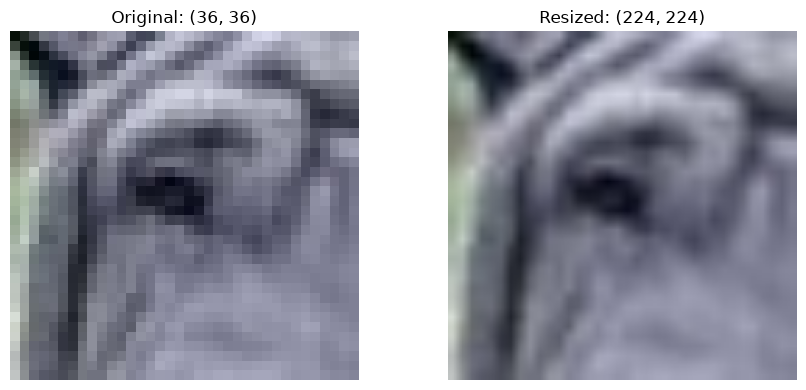

In [55]:
image_id = train.iloc[0]["image_id"]
image_path = DATA / "train" / "train" / f"{image_id}.jpg"

with Image.open(image_path) as image:
    original = image.convert("RGB")

resized = transforms.Resize((224, 224))(original)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(original)
axes[0].set_title(f"Original: {original.size}")

axes[1].imshow(resized)
axes[1].set_title(f"Resized: {resized.size}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

### 2.4.2 Pixel Normalisation

Pixel values are converted from 8-bit RGB values (0–255) into floating-point tensors (0–1).

ImageNet normalisation then standardises each colour channel using the mean and standard deviation associated with the pretrained ResNet18 weights.

In [56]:
# Convert the PIL image into a PyTorch tensor
tensor = transforms.ToTensor()(resized)

# ImageNet channel statistics
mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)

normalized = transforms.Normalize(mean, std)(tensor)

# Compare the same pixel at each stage
print("RGB pixel:", np.asarray(resized)[0, 0])
print("Tensor pixel:", tensor[:, 0, 0].numpy().round(3))
print("Normalised pixel:", normalized[:, 0, 0].numpy().round(3))

print("\nTensor shape:", tensor.shape)
print("Tensor range:", tensor.min().item(), "to", tensor.max().item())
print("Normalised range:", normalized.min().item(), "to", normalized.max().item())

RGB pixel: [ 5 15  6]
Tensor pixel: [0.02  0.059 0.024]
Normalised pixel: [-2.032 -1.773 -1.7  ]

Tensor shape: torch.Size([3, 224, 224])
Tensor range: 0.0 to 0.9254902005195618
Normalised range: -2.1179039478302 to 2.3088455200195312


### 2.4.3 Direct Resizing Versus Aspect-Preserving Cropping

The example below compares stretching an image directly to 224 × 224 with resizing while preserving its aspect ratio and taking a centre crop. Stretching changes proportions; cropping may exclude details near the edges. Neither operation restores detail missing from the original image.

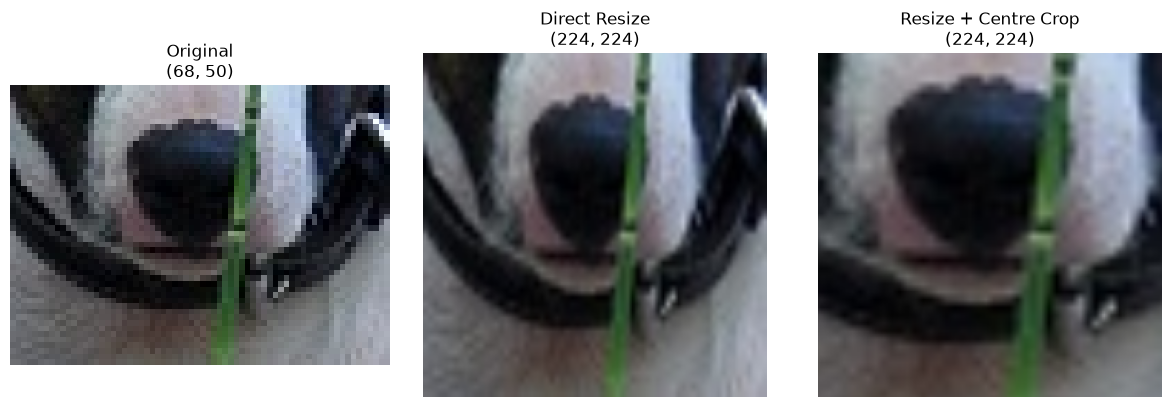

In [57]:
image_path = DATA / "train" / "train" / "09669.jpg"

with Image.open(image_path) as image:
    original = image.convert("RGB")

# Directly stretch to 224 × 224
stretched = transforms.Resize((224, 224))(original)

# Preserve aspect ratio, then crop the centre
cropped = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224)])(
    original
)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, image, title in zip(
    axes,
    [original, stretched, cropped],
    ["Original", "Direct Resize", "Resize + Centre Crop"],
):
    ax.imshow(image)
    ax.set_title(f"{title}\n{image.size}")
    ax.axis("off")

plt.tight_layout()
plt.show()


## 2.5 Data Augmentation


### 2.5.1 Training Transformations

The existing ResNet18 pipeline, defined in `src/enge707/data.py`, applies **RandomResizedCrop** to 224 × 224 pixels with a scale range of 0.8–1.0, **RandomHorizontalFlip**, and **ColorJitter** (brightness and contrast 0.15; saturation 0.1). It then converts images to tensors and applies ImageNet channel normalisation.

These random transformations introduce variation in framing, orientation and appearance. Their effectiveness must be assessed against model results rather than assumed from the visualisations alone.

### 2.5.2 Validation and Test Transformations

The evaluation pipeline uses deterministic preprocessing: resize the shorter side to 256 pixels, centre crop to 224 × 224, convert to a tensor and apply the same ImageNet normalisation. Random augmentation is excluded so repeated evaluation of the same image produces the same input tensor.

### 2.5.3 Augmentation Visualisation

The following figure uses the original image from Section 2.4.3 and shows four independently augmented views. The visualisation demonstrates the random image operations before tensor conversion and normalisation; it does not measure model accuracy.

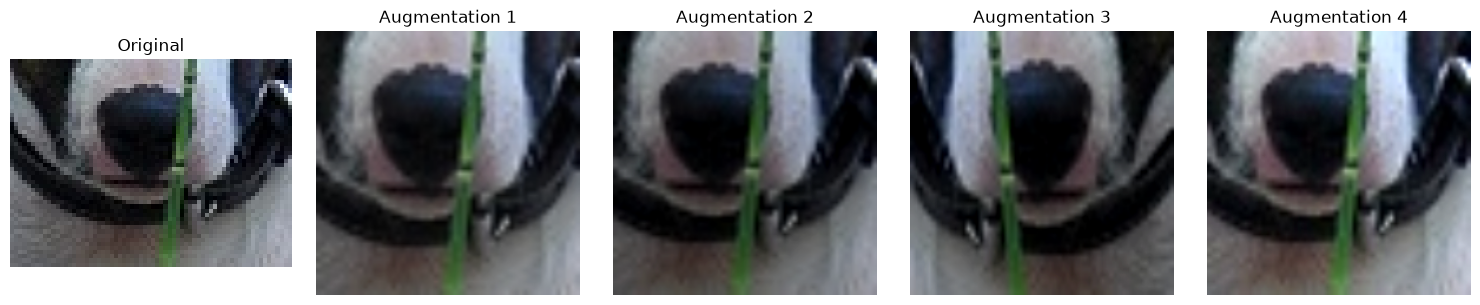

In [58]:
augmentation = transforms.Compose(
    [
        transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.1),
    ]
)

fig, axes = plt.subplots(1, 5, figsize=(15, 3))

axes[0].imshow(original)
axes[0].set_title("Original")

for i in range(1, 5):
    axes[i].imshow(augmentation(original))
    axes[i].set_title(f"Augmentation {i}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 2.6 Class Label Encoding

The eight class names are sorted alphabetically and assigned integer labels **0–7**, matching the class ordering used in the baseline training script. This mapping is then passed to the image dataset.

In [59]:
classes = sorted(train["class"].unique())
class_to_index = {name: i for i, name in enumerate(classes)}

display(pd.DataFrame(class_to_index.items(), columns=["Class", "Encoded Label"]))

,Class,Encoded Label
0,CatEye,0
1,CatFace,1
2,CatMouth,2
3,CatNose,3
4,DogEye,4
5,DogFace,5
6,DogMouth,6
7,DogNose,7


## 2.7 PyTorch Data Pipeline

The notebook reuses `FacialFeatureDataset` and `build_transforms` from the existing `src/enge707/data.py` module. This inspects the real baseline data-loading logic instead of creating a separate implementation.

### 2.7.1 Dataset

The dataset loads each image in RGB, applies the appropriate preprocessing transform, and returns its tensor alongside the numerically encoded class label.

In [60]:
train_transform, validation_transform = build_transforms()

image_dir = DATA / "train" / "train"

train_dataset = FacialFeatureDataset(train, image_dir, train_transform, class_to_index)

validation_dataset = FacialFeatureDataset(
    validation, image_dir, validation_transform, class_to_index
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(validation_dataset))

Training samples: 50928
Validation samples: 12732


### 2.7.2 DataLoader

DataLoaders combine individual examples into batches. This inspection uses a **batch size of 8**, shuffles the training set, and leaves the validation set in a fixed order. The baseline training script has a default training batch size of **32**; eight is used here only for a quick notebook check.

In [61]:
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=0)

validation_loader = DataLoader(
    validation_dataset, batch_size=8, shuffle=False, num_workers=0
)

### 2.7.3 Batch Inspection

Inspect one randomly selected training batch. Each image should have three colour channels and a spatial size of 224 × 224, with one integer class label per image. The label values will vary when the shuffled loader is rerun.

In [62]:
images, labels = next(iter(train_loader))

print("Images:", images.shape)
print("Labels:", labels.shape)
print("Class indices:", labels.tolist())
print("Data type:", images.dtype)

Images: torch.Size([8, 3, 224, 224])
Labels: torch.Size([8])
Class indices: [4, 4, 5, 4, 5, 4, 6, 0]
Data type: torch.float32


## 2.8 Pipeline Verification

The checks below confirm the saved dataset lengths, the sampled batch shape, encoded label bounds, and the repeatability of the **first validation image's** deterministic preprocessing. These are targeted checks, not a full validation of every image or a proof that all possible near-duplicate leakage has been eliminated.

In [63]:
assert len(train_dataset) == 50_928
assert len(validation_dataset) == 12_732
assert images.shape == (8, 3, 224, 224)
assert labels.min() >= 0
assert labels.max() < 8

# Deterministic validation preprocessing
image1, label1 = validation_dataset[0]
image2, label2 = validation_dataset[0]

assert torch.equal(image1, image2)
assert label1 == label2

print("All preprocessing checks passed.")

All preprocessing checks passed.


## 2.9 Findings and Limitations

The baseline preprocessing pipeline converts images of varied original sizes into **3 × 224 × 224** tensors using ImageNet normalisation. Training images receive random cropping, horizontal flipping and colour jitter; validation images use a deterministic resize-and-centre-crop pipeline.

The saved training and validation partitions contain **50,928** and **12,732** images respectively, with closely matched class proportions. Notebook 01 found no image-ID overlap or known exact-content duplicate groups crossing these partitions. The dataset and batch checks in this notebook also passed in the recorded outputs.

**Limitations**

- Resizing very small images cannot restore missing facial-feature detail; Notebook 01 found that approximately 91.8% of training images have at least one original side shorter than 224 pixels.
- Centre cropping can remove relevant content near image boundaries, while direct stretching can distort its appearance.
- Different crops of the same source photograph may evade exact-content duplicate checks.
- The visual augmentation experiment demonstrates possible transformations but **does not show an accuracy improvement**. Model comparisons are needed to evaluate their effectiveness.
- The verification cell checks only a sample batch and one repeated validation item, not every data sample.